In [1]:
!pip -q install pandas numpy scipy matplotlib scikit-learn openpyxl

In [2]:
from google.colab import files
print("Upload termiz_benchmark_results.zip")
uploaded = files.upload()
zip_path = next((name for name in uploaded if name.endswith(".zip")), None)
assert zip_path, "Please upload the ZIP archive."

Upload termiz_benchmark_results.zip


Saving termiz_benchmark_results.zip to termiz_benchmark_results.zip


In [3]:
"""Termiz PM2.5 benchmark: publication-oriented analysis without retraining.
Run in Colab: !pip -q install pandas numpy scipy matplotlib seaborn openpyxl
Then: %run analyze_termiz_results.py --zip termiz_benchmark_results.zip
"""
import argparse, io, json, os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({'figure.dpi':130,'savefig.dpi':180,'font.size':10})

def read_csv(z, filename):
    matches=[x for x in z.namelist() if x.endswith('/'+filename) or x==filename]
    if not matches: return None
    return pd.read_csv(io.BytesIO(z.read(matches[0])))

def metrics(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    good=np.isfinite(y)&np.isfinite(p);y=y[good];p=p[good]
    if len(y)==0:return {'n':0,'MAE':np.nan,'RMSE':np.nan,'R2':np.nan,'sMAPE_percent':np.nan,'bias':np.nan}
    return {'n':len(y),'MAE':mean_absolute_error(y,p),
            'RMSE':np.sqrt(mean_squared_error(y,p)),
            'R2':r2_score(y,p) if len(y)>1 and np.var(y)>0 else np.nan,
            'sMAPE_percent':np.mean(200*np.abs(y-p)/(np.abs(y)+np.abs(p)+1e-8)),
            'bias':np.mean(p-y)}

def save_plot(path):plt.tight_layout();plt.savefig(path,bbox_inches='tight');plt.close()

def run(zip_path,outdir):
    out=Path(outdir);out.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        pred=read_csv(z,'all_predictions_by_origin_lead.csv')
        if pred is None:raise FileNotFoundError('all_predictions_by_origin_lead.csv not found')
        original=read_csv(z,'model_comparison.csv')
        ablation=read_csv(z,'ablation_metadata.csv')
        splits=read_csv(z,'split_metadata.csv')
        quality=[n for n in z.namelist() if n.endswith('/data_quality.json')]
        if quality:
            with open(out/'data_quality.json','w') as f:json.dump(json.loads(z.read(quality[0])),f,indent=2)
        loss_names=[n for n in z.namelist() if '/loss_' in n and n.endswith('.csv')]
        losses={Path(n).stem:pd.read_csv(io.BytesIO(z.read(n))) for n in loss_names}
    pred['date']=pd.to_datetime(pred['date']);pred['origin']=pd.to_datetime(pred['origin'])
    pred['lead']=pd.to_numeric(pred['lead']);pred['horizon']=pd.to_numeric(pred['horizon'])
    pred=pred.dropna(subset=['actual','predicted','date','origin','model','lead','horizon'])
    pred['residual']=pred['predicted']-pred['actual'];pred['abs_error']=pred['residual'].abs()
    pred['month']=pred['date'].dt.month
    pred.to_csv(out/'predictions_with_errors.csv',index=False)
    # Quality audit: each target date must have a single prediction for each model and horizon.
    dup=pred.duplicated(['model','horizon','date']).sum()
    invalid_lead=(pred['lead']<1).sum()+(pred['lead']>pred['horizon']).sum()
    inconsistent=(pred['date']-pred['origin']).dt.days.ne(pred['lead']-1).sum()
    groups=pred.groupby(['model','horizon'])
    audits=[]
    for (m,h),g in groups:
        audits.append({'model':m,'horizon':h,'rows':len(g),'unique_target_dates':g.date.nunique(),
                       'unique_origins':g.origin.nunique(),'start':g.date.min().date(),'end':g.date.max().date(),
                       'duplicate_target_dates':g.date.duplicated().sum()})
    pd.DataFrame(audits).to_csv(out/'evaluation_audit.csv',index=False)
    if dup or invalid_lead or inconsistent:
        warnings.warn(f'Audit problems: duplicate dates={dup}, invalid leads={invalid_lead}, date-origin mismatches={inconsistent}')
    # Recalculate metrics from raw predictions; do not rely only on summary CSV.
    rows=[]
    for (m,h),g in groups:
        rows.append({'model':m,'horizon':int(h),**metrics(g.actual,g.predicted),'n_origins':g.origin.nunique()})
    summary=pd.DataFrame(rows).sort_values(['horizon','MAE'])
    summary.to_csv(out/'recomputed_model_comparison.csv',index=False)
    if original is not None:
        comparison=summary.merge(original,on=['model','horizon'],how='left',suffixes=('_recomputed','_archive'))
        for col in ['MAE','RMSE','R2','sMAPE_percent']:
            comparison[col+'_difference']=comparison[col+'_recomputed']-comparison[col+'_archive']
        comparison.to_csv(out/'archive_metric_consistency.csv',index=False)
    lead_rows=[]
    for (m,h,lead),g in pred.groupby(['model','horizon','lead']):
        lead_rows.append({'model':m,'horizon':h,'lead':lead,**metrics(g.actual,g.predicted)})
    per_lead=pd.DataFrame(lead_rows)
    per_lead.to_csv(out/'recomputed_per_lead_metrics.csv',index=False)
    # Shared date intersection ACROSS ALL horizons; compare only common targets, and explicitly retain differing lead times.
    common=set.intersection(*(set(g.date.unique()) for _,g in pred.groupby('horizon')))
    common_pred=pred[pred.date.isin(common)].copy()
    common_rows=[]
    for (m,h),g in common_pred.groupby(['model','horizon']):
        common_rows.append({'model':m,'horizon':h,**metrics(g.actual,g.predicted)})
    pd.DataFrame(common_rows).sort_values(['horizon','MAE']).to_csv(out/'common_dates_comparison.csv',index=False)
    # Also match SAME lead (1..7) and common dates, for a fair horizon-model comparison.
    leadmax=min(pred.horizon.unique())
    samelead=pred[pred.lead<=leadmax].copy()
    keys=None
    for h,g in samelead.groupby('horizon'):
        s=set(zip(g.date,g.lead));keys=s if keys is None else keys&s
    mask=[(d,l) in keys for d,l in zip(samelead.date,samelead.lead)]
    matched=samelead.loc[mask]
    matched_rows=[]
    for (m,h),g in matched.groupby(['model','horizon']):
        matched_rows.append({'model':m,'horizon':h,**metrics(g.actual,g.predicted)})
    pd.DataFrame(matched_rows).sort_values(['horizon','MAE']).to_csv(out/'same_dates_same_leads_comparison.csv',index=False)
    # Error by month and by pollution concentration quantiles.
    monthly=[]
    for (m,h,mo),g in pred.groupby(['model','horizon','month']):
        monthly.append({'model':m,'horizon':h,'month':mo,**metrics(g.actual,g.predicted)})
    pd.DataFrame(monthly).to_csv(out/'monthly_error_recomputed.csv',index=False)
    pred['pollution_bin']=pd.cut(pred.actual,[-np.inf,15,35,75,np.inf],labels=['<=15','15-35','35-75','>75'])
    bins=[]
    for (m,h,b),g in pred.groupby(['model','horizon','pollution_bin'],observed=True):
        bins.append({'model':m,'horizon':h,'pm25_band':str(b),**metrics(g.actual,g.predicted)})
    pd.DataFrame(bins).to_csv(out/'pollution_level_errors.csv',index=False)
    # Paired bootstrap of per-origin average abs errors (not treating overlapping forecasts as independent).
    rng=np.random.default_rng(42); bootstrap=[]
    for h in sorted(pred.horizon.unique()):
        subset=pred[pred.horizon==h]
        pivot=subset.groupby(['origin','model']).abs_error.mean().unstack('model')
        target='PatchTST_univariate'
        if target not in pivot:continue
        for competitor in pivot.columns:
            if competitor==target:continue
            pair=pivot[[target,competitor]].dropna()
            if len(pair)<3:continue
            d=(pair[competitor]-pair[target]).to_numpy() # positive means PatchTST better
            samples=rng.choice(d,(2000,len(d)),replace=True).mean(axis=1)
            bootstrap.append({'horizon':h,'baseline':competitor,'n_origins':len(d),
                'baseline_minus_patchtst_MAE':d.mean(),
                'bootstrap_CI_2_5':np.percentile(samples,2.5),
                'bootstrap_CI_97_5':np.percentile(samples,97.5),
                'bootstrap_note':'Exploratory origin-resampling; serial dependence may make intervals optimistic'})
    pd.DataFrame(bootstrap).to_csv(out/'paired_origin_bootstrap.csv',index=False)
    # Chart 1: model comparison for each horizon.
    for h in sorted(pred.horizon.unique()):
        s=summary[summary.horizon==h].sort_values('MAE')
        plt.figure(figsize=(9,4.5));plt.barh(s.model,s.MAE);plt.gca().invert_yaxis()
        plt.xlabel('MAE (µg/m³)');plt.title(f'Model comparison, horizon={h} days (n={int(s.n.iloc[0])} dates)')
        save_plot(out/f'model_mae_h{h}.png')
    # Chart 2: horizon error, one panel per forecast horizon.
    for h in sorted(pred.horizon.unique()):
        s=per_lead[per_lead.horizon==h]
        plt.figure(figsize=(10,5))
        for model,g in s.groupby('model'):
            plt.plot(g.lead,g.MAE,label=model,linewidth=1.7)
        plt.xlabel('Forecast lead (days)');plt.ylabel('MAE (µg/m³)');plt.title(f'Error by forecast lead — horizon {h}')
        plt.legend(fontsize=8,ncol=2);plt.grid(alpha=.2)
        save_plot(out/f'lead_mae_h{h}.png')
    # Chart 3: actual vs predicted, 30d horizon (unique dates).
    h=max(pred.horizon.unique());g=pred[(pred.horizon==h)&(pred.model=='PatchTST_univariate')].sort_values('date')
    if len(g):
        plt.figure(figsize=(13,5));plt.plot(g.date,g.actual,label='Actual',linewidth=1.3)
        plt.plot(g.date,g.predicted,label='PatchTST',linewidth=1.2)
        plt.xlabel('Date');plt.ylabel('PM₂.₅ (µg/m³)');plt.title(f'Actual vs PatchTST (h={h}, n={len(g)})')
        plt.legend();plt.grid(alpha=.2);save_plot(out/'actual_vs_patchtst_h30.png')
        plt.figure(figsize=(10,4.5));plt.scatter(g.actual,g.predicted,alpha=.5,s=14)
        lo=min(g.actual.min(),g.predicted.min());hi=max(g.actual.max(),g.predicted.max())
        plt.plot([lo,hi],[lo,hi],'k--',linewidth=1)
        plt.xlabel('Actual PM₂.₅');plt.ylabel('Predicted PM₂.₅');plt.title('Calibration scatter — PatchTST')
        save_plot(out/'actual_vs_predicted_scatter.png')
        plt.figure(figsize=(10,4));plt.scatter(g.predicted,g.residual,alpha=.5,s=15)
        plt.axhline(0,color='black',linestyle='--');plt.xlabel('Predicted PM₂.₅');plt.ylabel('Prediction minus actual')
        plt.title('Residual diagnostic — PatchTST');save_plot(out/'residual_scatter.png')
    # Chart 4: learning curves and selected validation minimum.
    for name,loss in losses.items():
        if not {'epoch','train_loss','val_loss'}.issubset(loss):continue
        plt.figure(figsize=(8,4));plt.plot(loss.epoch,loss.train_loss,label='Train')
        plt.plot(loss.epoch,loss.val_loss,label='Validation')
        best_epoch=int(loss.loc[loss.val_loss.idxmin(),'epoch'])
        plt.axvline(best_epoch,linestyle='--',color='gray',label=f'Best val epoch {best_epoch}')
        plt.xlabel('Epoch');plt.ylabel('Loss');plt.title(name.replace('_',' '));plt.legend();plt.grid(alpha=.2)
        save_plot(out/(name+'.png'))
    if ablation is not None:ablation.to_csv(out/'ablation_metadata.csv',index=False)
    if splits is not None:splits.to_csv(out/'split_metadata.csv',index=False)
    # Explicit limitations, avoid claiming untested multivariate effects.
    notes=[f'Total prediction rows: {len(pred)}',f'Duplicate target dates within model/horizon: {dup}',
           f'Date-origin-lead inconsistencies: {inconsistent}',
           f'Common target dates across all horizons: {len(common)}',
           f'Common (date, lead) pairs across all horizons: {len(keys)}',
           'Different horizons have different date coverage and forecast-lead composition.',
           'Bootstrap uses forecast origins as units; origins may be temporally dependent.',
           'sMAPE and MAPE are different metrics and cannot be directly compared.',
           'If ablation_metadata lists only univariate channels, do not claim multivariate experiments.',
           'This script analyzes archived predictions; it does not independently verify training leakage or dataset provenance.']
    (out/'READ_ME_FIRST.txt').write_text('\n'.join(notes),encoding='utf-8')
    print('\n'.join(notes))
    print('\nRECOMPUTED SUMMARY\n',summary.to_string(index=False,float_format=lambda x:f'{x:.3f}'))
    print('\nFiles saved in:',out.resolve())
    archive=out.parent/(out.name+'.zip')
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
        for f in out.rglob('*'):
            if f.is_file():z.write(f,arcname=f.relative_to(out.parent))
    print('Download archive:',archive.resolve())
    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:pass



In [4]:
run(zip_path, "termiz_analysis")

Total prediction rows: 4284
Duplicate target dates within model/horizon: 0
Date-origin-lead inconsistencies: 0
Common target dates across all horizons: 98
Common (date, lead) pairs across all horizons: 98
Different horizons have different date coverage and forecast-lead composition.
Bootstrap uses forecast origins as units; origins may be temporally dependent.
sMAPE and MAPE are different metrics and cannot be directly compared.
If ablation_metadata lists only univariate channels, do not claim multivariate experiments.
This script analyzes archived predictions; it does not independently verify training leakage or dataset provenance.

RECOMPUTED SUMMARY
               model  horizon   n    MAE   RMSE     R2  sMAPE_percent    bias  n_origins
PatchTST_univariate        7  98 23.649 32.595  0.008         31.749  -3.250         14
              Ridge        7  98 24.127 34.674 -0.123         32.739 -11.375         14
            XGBoost        7  98 27.875 39.214 -0.436         38.299 -22.7

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,model,horizon,n,MAE,RMSE,R2,sMAPE_percent,bias,n_origins
0,PatchTST_univariate,7,98,23.648976,32.595393,0.008002,31.748545,-3.249882,14
1,Ridge,7,98,24.127339,34.674203,-0.122564,32.738595,-11.374945,14
2,XGBoost,7,98,27.875328,39.214173,-0.435768,38.298691,-22.754240,14
3,LSTM,7,98,28.934376,41.075104,-0.575272,39.968280,-24.883118,14
4,Persistence,7,98,31.568260,46.885390,-1.052454,37.625127,7.497283,14
5,SeasonalNaive365,7,98,31.641506,43.636489,-0.777861,46.015535,-21.958608,14
6,PatchTST_univariate,14,196,20.545603,29.269750,0.204789,28.151738,-4.894214,14
7,Ridge,14,196,24.253965,35.406568,-0.163623,32.679072,-12.228964,14
8,XGBoost,14,196,27.069693,38.971392,-0.409732,37.100175,-21.595329,14
9,LSTM,14,196,28.579679,41.223576,-0.577379,39.546964,-25.275258,14


,model,horizon,n,MAE,RMSE,R2,sMAPE_percent,bias
0,PatchTST_univariate,7,98,23.648976,32.595393,0.008002,31.748545,-3.249882
1,Ridge,7,98,24.127339,34.674203,-0.122564,32.738595,-11.374945
2,XGBoost,7,98,27.875328,39.214173,-0.435768,38.298691,-22.754240
3,LSTM,7,98,28.934376,41.075104,-0.575272,39.968280,-24.883118
4,Persistence,7,98,31.568260,46.885390,-1.052454,37.625127,7.497283
5,SeasonalNaive365,7,98,31.641506,43.636489,-0.777861,46.015535,-21.958608
6,PatchTST_univariate,14,98,23.101876,31.939195,0.047541,31.720886,-5.957924
7,Ridge,14,98,24.544293,35.060325,-0.147705,33.513871,-11.496540
8,XGBoost,14,98,27.432966,38.892405,-0.412303,37.567974,-22.218361
9,LSTM,14,98,29.147067,41.443360,-0.603645,40.316454,-25.681484


,model,horizon,n,MAE,RMSE,R2,sMAPE_percent,bias
0,PatchTST_univariate,7,98,23.648976,32.595393,0.008002,31.748545,-3.249882
1,Ridge,7,98,24.127339,34.674203,-0.122564,32.738595,-11.374945
2,XGBoost,7,98,27.875328,39.214173,-0.435768,38.298691,-22.754240
3,LSTM,7,98,28.934376,41.075104,-0.575272,39.968280,-24.883118
4,Persistence,7,98,31.568260,46.885390,-1.052454,37.625127,7.497283
5,SeasonalNaive365,7,98,31.641506,43.636489,-0.777861,46.015535,-21.958608
6,PatchTST_univariate,14,98,23.101876,31.939195,0.047541,31.720886,-5.957924
7,Ridge,14,98,24.544293,35.060325,-0.147705,33.513871,-11.496540
8,XGBoost,14,98,27.432966,38.892405,-0.412303,37.567974,-22.218361
9,LSTM,14,98,29.147067,41.443360,-0.603645,40.316454,-25.681484


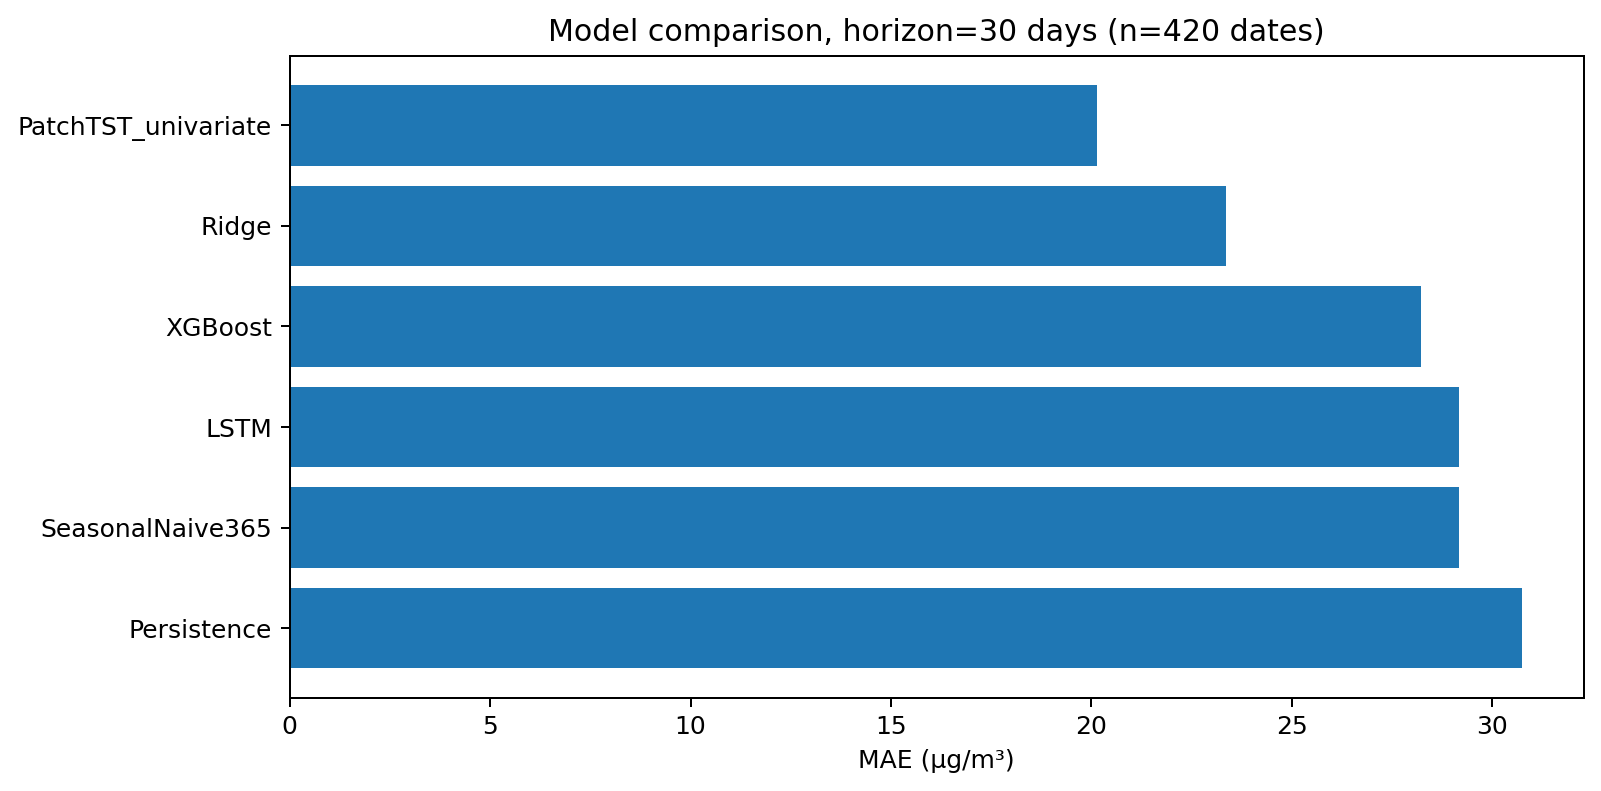

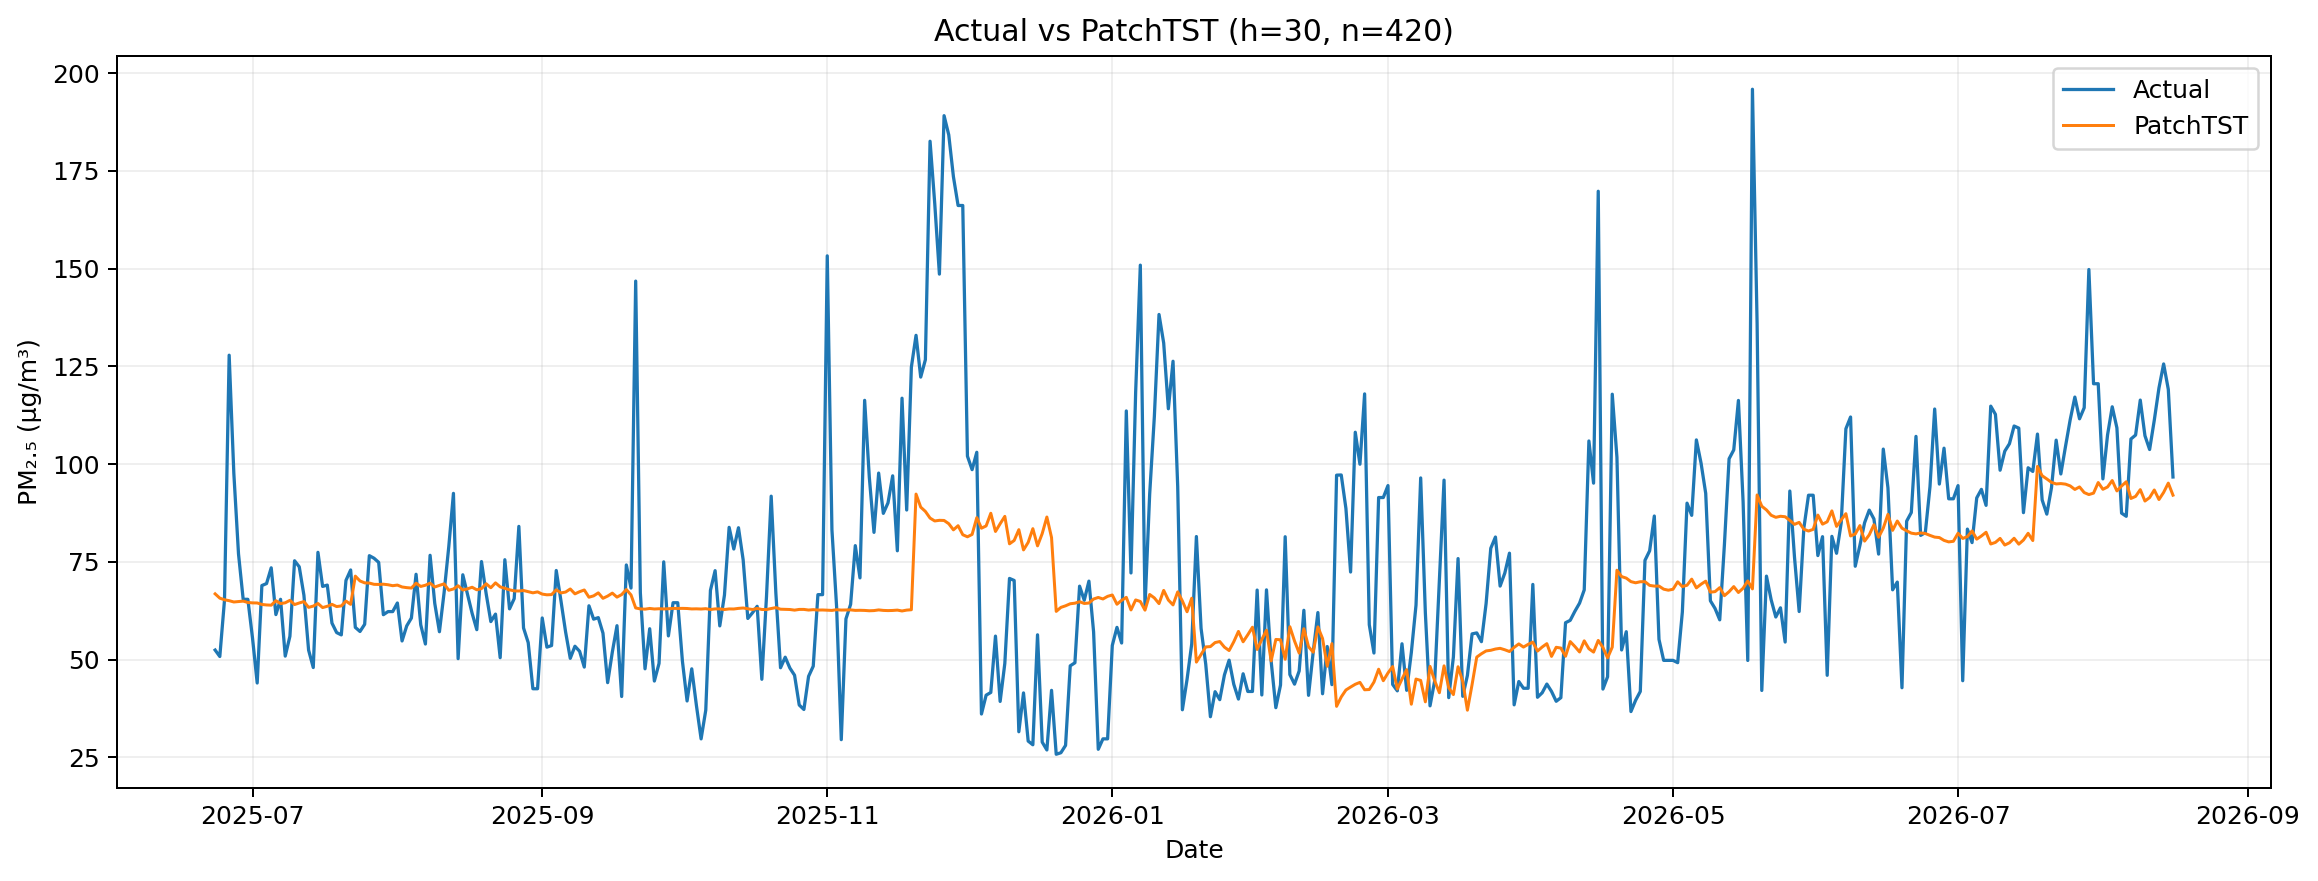

In [5]:
from IPython.display import display, Image
import pandas as pd
display(pd.read_csv("termiz_analysis/recomputed_model_comparison.csv"))
display(pd.read_csv("termiz_analysis/common_dates_comparison.csv"))
display(pd.read_csv("termiz_analysis/same_dates_same_leads_comparison.csv"))
display(Image(filename="termiz_analysis/model_mae_h30.png"))
display(Image(filename="termiz_analysis/actual_vs_patchtst_h30.png"))